In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import fabio
import matplotlib.patches as patches

In [2]:
data_dir = r"C:\Users\j.bantol\Documents\Outputs\Beamtimes\Akhlak"

Found 101 frames


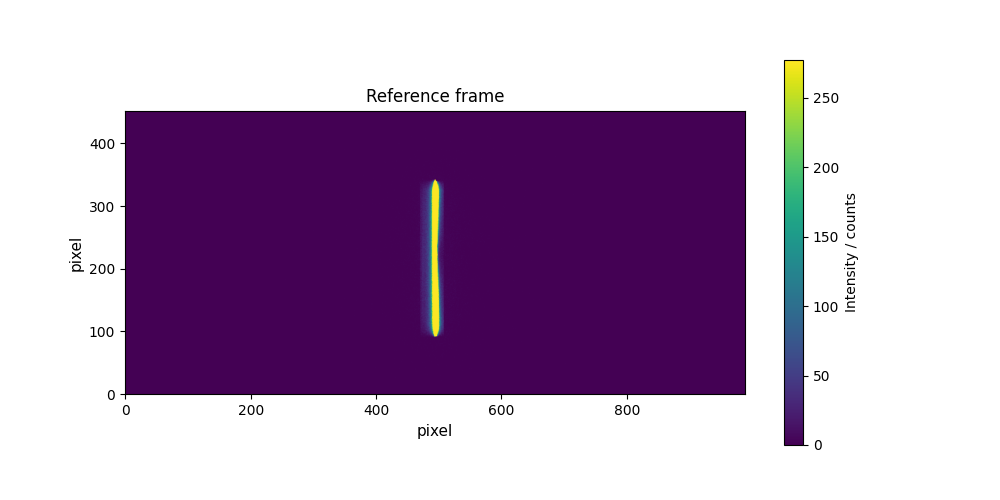

In [3]:
%matplotlib widget
plt.close("all")

frames = sorted(
    (f for f in os.listdir(data_dir_1) if f.endswith(".png")),
    key=lambda f: int(f.rsplit("_", 1)[1].split(".")[0]),   # Frame_1000.gfrm -> 1000
)

print(f"Found {len(frames)} frames")

# step 1: plot reference frame to choose ROI
ref_obj = fabio.open(os.path.join(data_dir_1, frames[0]))
ref_data = ref_obj.data

fig, ax = plt.subplots(figsize=(10, 5))
img = ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower", cmap="viridis")
plt.colorbar(img, ax=ax, label="Intensity / counts")


ax.set_title(f"Reference frame", fontsize="12")
ax.set_xlabel(f"pixel", fontsize="11")
ax.set_ylabel(f"pixel", fontsize="11")
plt.show()

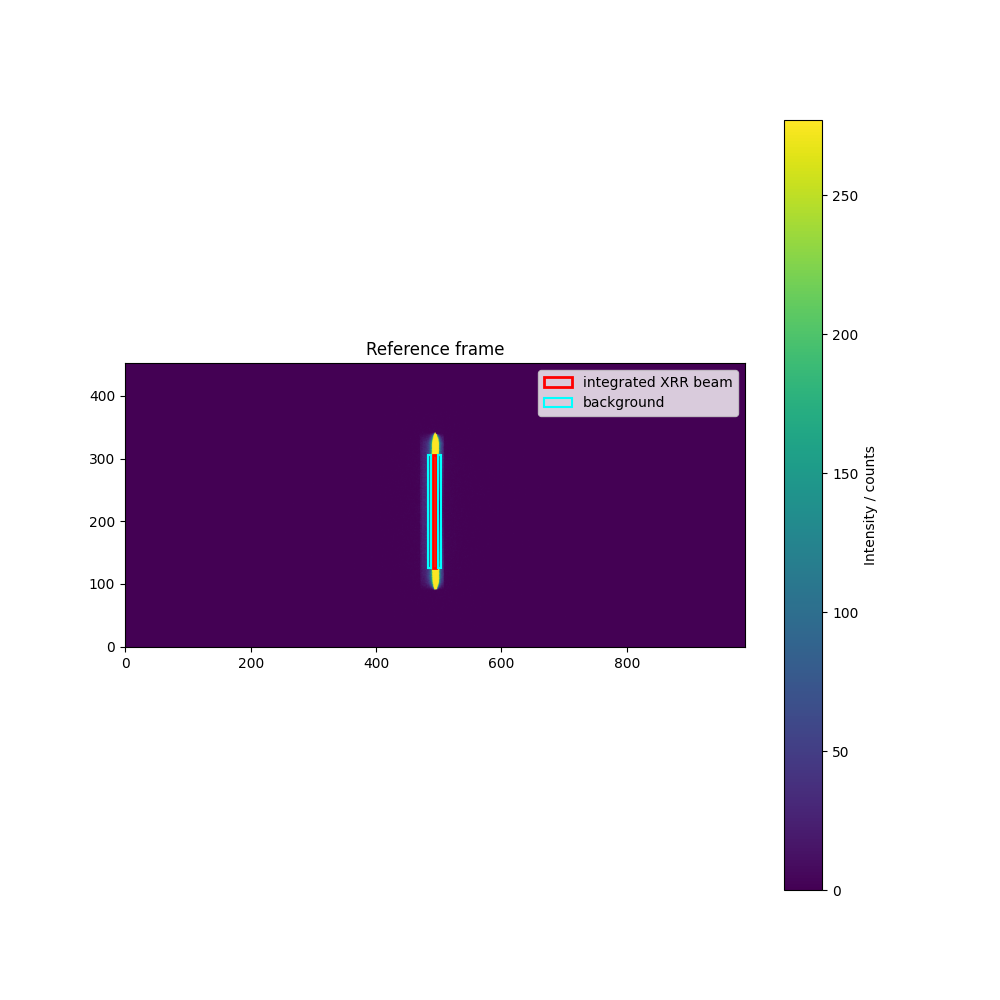

In [5]:
# step 2: set ROI manually
x0, x1 = 490.5, 495.5   # column range
y0, y1 = 126, 306   # row range

# bg ROIs: same width and y-range as signal, placed left and right
sig_width = x1 - x0
gap = 3  # px

x0_bg_left  = x0 - gap - sig_width
x1_bg_left  = x0 - gap
x0_bg_right = x1 + gap
x1_bg_right = x1 + gap + sig_width
y0_bg, y1_bg = y0, y1

# verify ROI overlay
fig, ax = plt.subplots(figsize=(10, 10))
img=ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower")
plt.colorbar(img, ax=ax, label="Intensity / counts")

ax.add_patch(patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=2, edgecolor="red", facecolor="none", label="integrated XRR beam"))
ax.add_patch(patches.Rectangle((x0_bg_left, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none", label="background"))
ax.add_patch(patches.Rectangle((x0_bg_right, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none"))
ax.legend(loc="upper right")
ax.set_title("Reference frame")
plt.show()

In [19]:
# step 3: apply ROI to all frames, extract 2theta, integrate ROI
x0, x1 = int(x0), int(x1)
y0, y1 = int(y0), int(y1)

x0_bg_left, x1_bg_left = int(x0_bg_left), int(x1_bg_left)
x0_bg_right, x1_bg_right = int(x0_bg_right), int(x1_bg_right)
y0_bg, y1_bg = int(y0_bg), int(y1_bg)

start_angle = 0   # starting 2theta
step_size = 0.005   # degrees per frame

results = []
for i, f in enumerate(frames):
    obj = fabio.open(os.path.join(data_dir_1, f))
    data = obj.data
    roi_sum = data[y0:y1, x0:x1].sum()
    
    sig   = data[y0:y1, x0:x1].sum()
    bg_l  = data[y0_bg:y1_bg, x0_bg_left:x1_bg_left].sum()
    bg_r  = data[y0_bg:y1_bg, x0_bg_right:x1_bg_right].sum()
    bg_avg = (bg_l + bg_r) / 2
    
    t = float(obj.header["ELAPSDR"])   # count time based on header (1s for data_dir_1 and 3s for data_dir_2)

    two_theta = start_angle + i * step_size
    #results.append((two_theta, sig, bg_avg))
    results.append((two_theta, sig / t, bg_avg / t))

two_thetas_1 = np.array([r[0] for r in results])
roi_sums_1 = np.array([r[1] for r in results])
bg_avgs_1 = np.array([r[2] for r in results])

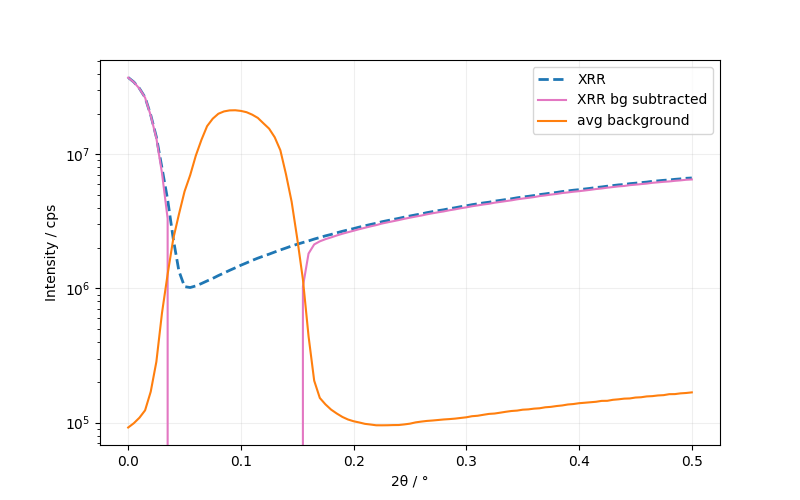

In [20]:
# step 4: plot ROI intensity vs. scattering angle
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas_1, roi_sums_1, "--", lw=2, color="C0", label="XRR")
ax.plot(two_thetas_1, roi_sums_1 - bg_avgs_1, color="C6", label="XRR bg subtracted")
ax.plot(two_thetas_1, bg_avgs_1, color="C1", label="avg background")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / cps")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

Found 1501 frames


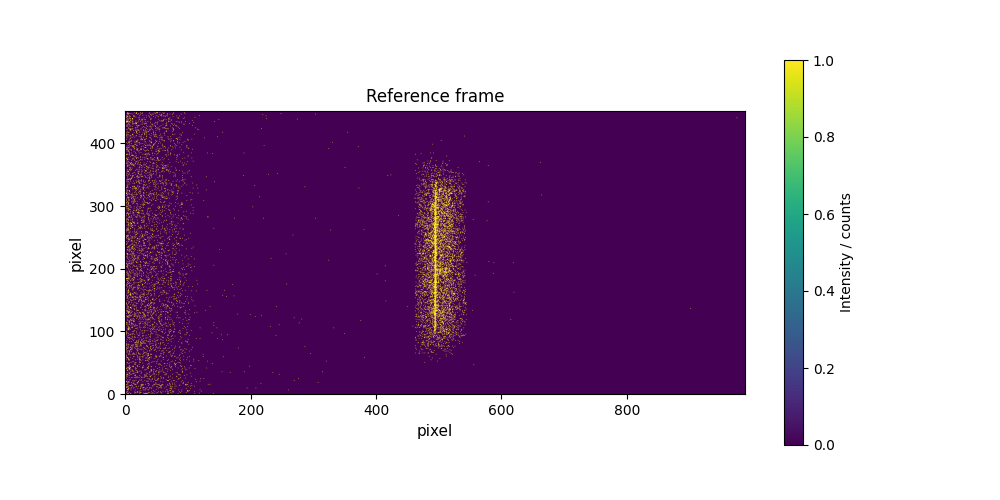

In [41]:
plt.close("all")

frames = sorted(
    (f for f in os.listdir(data_dir_2) if f.endswith(".gfrm")),
    key=lambda f: int(f.rsplit("_", 1)[1].split(".")[0]),   # Frame_1000.gfrm -> 1000
)

print(f"Found {len(frames)} frames")

# step 1: plot reference frame to choose ROI
ref_obj = fabio.open(os.path.join(data_dir_2, frames[800]))
ref_data = ref_obj.data

fig, ax = plt.subplots(figsize=(10, 5))
img = ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower", cmap="viridis")
plt.colorbar(img, ax=ax, label="Intensity / counts")


ax.set_title(f"Reference frame", fontsize="12")
ax.set_xlabel(f"pixel", fontsize="11")
ax.set_ylabel(f"pixel", fontsize="11")
plt.show()

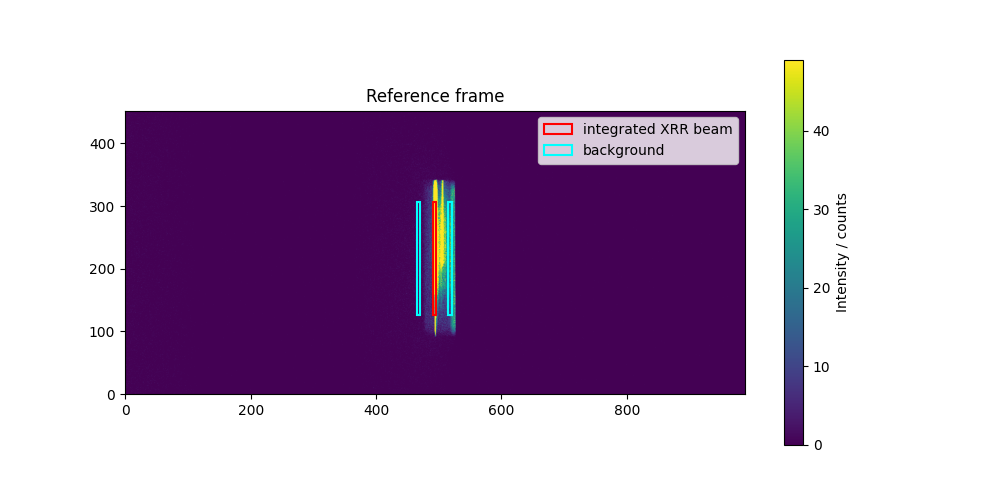

In [39]:
# step 2: set ROI manually
x0, x1 = 490.5, 495.5   # column range
y0, y1 = 126, 306   # row range

# bg ROIs: same width and y-range as signal, placed left and right
sig_width = x1 - x0
gap = 20   # px

x0_bg_left  = x0 - gap - sig_width
x1_bg_left  = x0 - gap
x0_bg_right = x1 + gap
x1_bg_right = x1 + gap + sig_width
y0_bg, y1_bg = y0, y1

# verify ROI overlay
fig, ax = plt.subplots(figsize=(10, 5))
img=ax.imshow(ref_data, vmax=np.percentile(ref_data, 99.5), origin="lower")
plt.colorbar(img, ax=ax, label="Intensity / counts")

ax.add_patch(patches.Rectangle((x0, y0), x1-x0, y1-y0, linewidth=1.5, edgecolor="red", facecolor="none", label="integrated XRR beam"))
ax.add_patch(patches.Rectangle((x0_bg_left, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none", label="background"))
ax.add_patch(patches.Rectangle((x0_bg_right, y0_bg), sig_width, y1_bg-y0_bg,linewidth=1.5, edgecolor="cyan", facecolor="none"))
ax.legend(loc="upper right")
ax.set_title("Reference frame")
plt.show()

In [34]:
# step 3: apply ROI to all frames, extract 2theta, integrate ROI
x0, x1 = int(x0), int(x1)
y0, y1 = int(y0), int(y1)

x0_bg_left, x1_bg_left = int(x0_bg_left), int(x1_bg_left)
x0_bg_right, x1_bg_right = int(x0_bg_right), int(x1_bg_right)
y0_bg, y1_bg = int(y0_bg), int(y1_bg)

start_angle = 0.5   # starting 2theta
step_size = 0.003   # degrees per frame

results = []
for i, f in enumerate(frames):
    obj = fabio.open(os.path.join(data_dir_2, f))
    data = obj.data
    roi_sum = data[y0:y1, x0:x1].sum()
    
    sig   = data[y0:y1, x0:x1].sum()
    bg_l  = data[y0_bg:y1_bg, x0_bg_left:x1_bg_left].sum()
    bg_r  = data[y0_bg:y1_bg, x0_bg_right:x1_bg_right].sum()
    bg_avg = (bg_l + bg_r) / 2
    
    t = float(obj.header["ELAPSDR"])   # count time based on header (1s for data_dir_1 and 3s for data_dir_2)

    two_theta = start_angle + i * step_size
    #results.append((two_theta, sig, bg_avg))
    results.append((two_theta, sig / t, bg_avg / t, bg_l / t, bg_r / t))
    
two_thetas_2 = np.array([r[0] for r in results])
roi_sums_2 = np.array([r[1] for r in results])
bg_avgs_2 = np.array([r[2] for r in results])
bg_l_2 = np.array([r[3] for r in results])
bg_r_2 = np.array([r[4] for r in results])

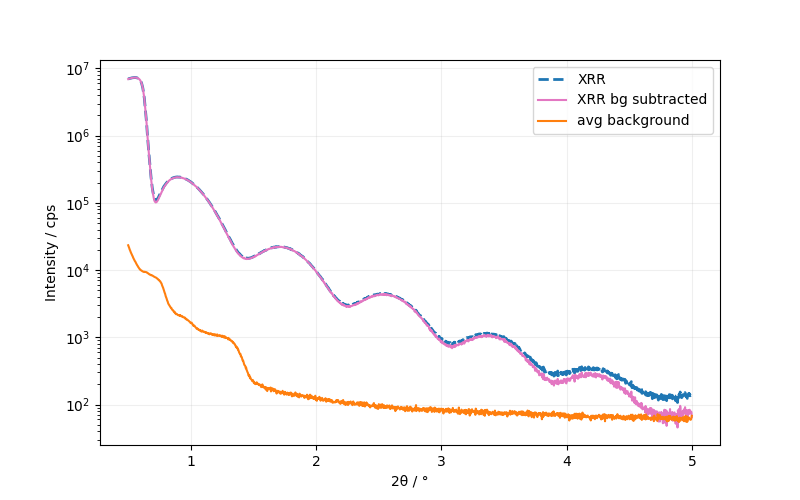

In [35]:
# step 4: plot ROI intensity vs. scattering angle
%matplotlib widget
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas_2, roi_sums_2, "--", lw=2, color="C0", label="XRR")
ax.plot(two_thetas_2, roi_sums_2 - bg_avgs_2, color="C6", label="XRR bg subtracted")
ax.plot(two_thetas_2, bg_avgs_2, color="C1", label="avg background")
#ax.plot(two_thetas_2, bg_l_2, color="C2", label="bg left")
#ax.plot(two_thetas_2, bg_r_2, color="C3", label="bg right")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / cps")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

In [30]:
# combine both scans
two_thetas = np.concatenate([two_thetas_1, two_thetas_2])
roi_sums = np.concatenate([roi_sums_1, roi_sums_2])
bg_avgs = np.concatenate([bg_avgs_1, bg_avgs_2])

# sort by 2theta so the line is continuous across the 0.3° stitch point
order = np.argsort(two_thetas, kind="stable")
two_thetas, roi_sums, bg_avgs = two_thetas[order], roi_sums[order], bg_avgs[order]

In [31]:
%matplotlib inline
plt.close("all")

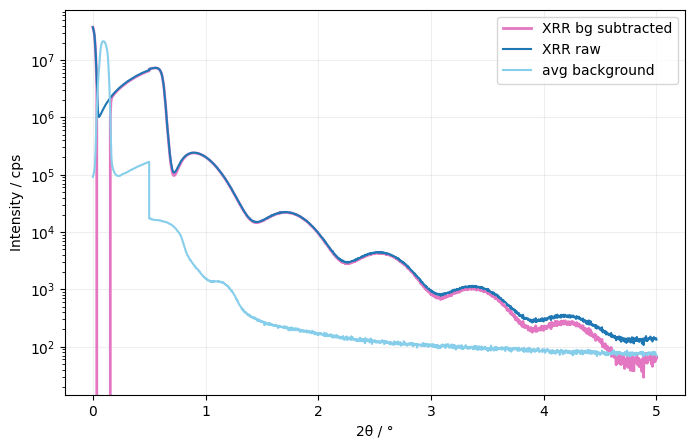

In [32]:
# step 5: plot combined, normalized ROI intensity vs. scattering angle
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(two_thetas, roi_sums - bg_avgs, lw=2, color="C6",  label="XRR bg subtracted")
ax.plot(two_thetas, roi_sums, color="C0", label="XRR raw")
ax.plot(two_thetas, bg_avgs, color="skyblue", label="avg background")
#ax.axvline(two_thetas_2[0], color="gray", ls=":", lw=1, label=f"scan stitch ({count_time_1} s → {count_time_2} s)")

ax.set_xlabel("2θ / °")
ax.set_ylabel("Intensity / cps")
ax.set_yscale("log")

plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

## Fresnel reflectivity from the combined 2D XRR map (PNG)
The map is a rendered matplotlib figure: x = detector pixel, y = grazing angle,
colour = log(reflectivity) on the colorbar scale. Each grazing-angle row is
turned back into numbers by inverting the viridis colormap, then the reflectivity
of that row is summed over all detector pixels it lands on (curvature spreads
the beam over many pixels), giving R(theta).

In [ ]:
from PIL import Image
from matplotlib import colormaps

map_png = os.path.join(data_dir, "combined_xrr_map.png")   # the "Combined XRR map w=... R=..." image

# --- calibration read off the figure (edit if the figure changes) ---
# axes ticks:   (pixel row in the PNG, value)  - auto-detected below, values typed in
x_tick_values  = [250, 500, 750, 1000, 1250, 1500, 1750]  # detector pixel ticks, left -> right
y_tick_values  = [5, 4, 3, 2, 1]                  # grazing angle ticks, top -> bottom
cb_tick_values = [-6, -8, -10, -12, -14, -16, -18]  # colorbar ticks, top -> bottom
log_base = 10      # colorbar is log10(R); set to np.e if it is ln(R)
cmap_name = "viridis"
max_color_dist = 12  # RGB distance; pixels further from the colormap (white bg, grey edge) are dropped

img_rgb = np.asarray(Image.open(map_png).convert("RGB")).astype(float)
dark = img_rgb.sum(axis=2) < 200

def find_frames(dark):
    """Locate the main axes box and the colorbar box from their black outlines."""
    rows = np.where(dark.sum(axis=1) > 0.3 * dark.shape[1])[0]
    cols = np.where(dark.sum(axis=0) > 0.3 * dark.shape[0])[0]
    top, bottom = rows.min(), rows.max()
    assert len(cols) == 4, f"expected 4 vertical spines (axes + colorbar), found columns {cols}"
    ax_left, ax_right, cb_left, cb_right = cols
    return top, bottom, ax_left, ax_right, cb_left, cb_right

top, bottom, ax_left, ax_right, cb_left, cb_right = find_frames(dark)

def tick_rows(col):
    """Rows of tick marks drawn just outside a vertical spine at column `col`."""
    r = np.where(dark[top:bottom + 1, col])[0] + top
    # collapse runs of adjacent pixels into one tick
    groups = np.split(r, np.where(np.diff(r) > 1)[0] + 1)
    return np.array([g.mean() for g in groups if len(g)])

def tick_cols(row):
    """Columns of tick marks drawn just below the bottom spine at row `row`."""
    c = np.where(dark[row, ax_left:ax_right + 1])[0] + ax_left
    groups = np.split(c, np.where(np.diff(c) > 1)[0] + 1)
    return np.array([g.mean() for g in groups if len(g)])

x_ticks_px  = tick_cols(bottom + 3)
y_ticks_px  = tick_rows(ax_left - 3)
assert len(x_ticks_px) == len(x_tick_values), f"found x ticks at columns {x_ticks_px}"
cb_ticks_px = tick_rows(cb_right + 3)
assert len(y_ticks_px) == len(y_tick_values), f"found y ticks at rows {y_ticks_px}"
assert len(cb_ticks_px) == len(cb_tick_values), f"found colorbar ticks at rows {cb_ticks_px}"

# linear pixel-row -> value maps
col_to_det   = np.poly1d(np.polyfit(x_ticks_px, x_tick_values, 1))
row_to_angle = np.poly1d(np.polyfit(y_ticks_px, y_tick_values, 1))
row_to_cb    = np.poly1d(np.polyfit(cb_ticks_px, cb_tick_values, 1))

# colour lookup table taken straight from the colorbar in the image (exact rendered colours)
cb_rows = np.arange(top + 1, bottom)
cb_rgb  = img_rgb[cb_rows, (cb_left + cb_right) // 2]
cb_val  = row_to_cb(cb_rows)
# densify with the true colormap over the same range for sub-row resolution
lut_val = np.linspace(cb_val.min(), cb_val.max(), 1024)
lut_rgb = colormaps[cmap_name]((lut_val - cb_val.min()) / (cb_val.max() - cb_val.min()))[:, :3] * 255
lut_val = np.concatenate([lut_val, cb_val])
lut_rgb = np.concatenate([lut_rgb, cb_rgb])

# invert the colormap for every pixel inside the axes
plot = img_rgb[top + 1:bottom, ax_left + 1:ax_right]
flat = plot.reshape(-1, 3)
best = np.empty(len(flat), dtype=int)
dist = np.empty(len(flat))
for s in range(0, len(flat), 5000):            # chunked to keep memory small
    d2 = ((flat[s:s + 5000, None, :] - lut_rgb[None, :, :]) ** 2).sum(axis=2)
    best[s:s + 5000] = d2.argmin(axis=1)
    dist[s:s + 5000] = np.sqrt(d2.min(axis=1))
log_R_map = lut_val[best].reshape(plot.shape[:2])
log_R_map[dist.reshape(plot.shape[:2]) > max_color_dist] = np.nan

angles  = row_to_angle(np.arange(top + 1, bottom))      # grazing angle of each map row, deg
det_px  = col_to_det(np.arange(ax_left + 1, ax_right))   # detector pixel of each map column
R_map = np.power(float(log_base), log_R_map)            # NaN outside the illuminated region
print(f"decoded map: {R_map.shape[0]} angle rows ({np.abs(np.diff(angles)).mean():.4f} deg/row), "
      f"{R_map.shape[1]} columns ({np.diff(det_px).mean():.2f} detector px/column)")

In [ ]:
# set ROI manually (same idea as the 1D XRR cells above, but in map coordinates)
x0, x1 = 900, 1100      # detector pixel range
y0, y1 = 0.0, 5.0       # grazing angle range, deg

# bg ROIs: same width and angle range as signal, placed left and right
sig_width = x1 - x0
gap = 20  # detector px
subtract_bg = False   # simulated map has no real background - set True for measured data

x0_bg_left  = x0 - gap - sig_width
x1_bg_left  = x0 - gap
x0_bg_right = x1 + gap
x1_bg_right = x1 + gap + sig_width
y0_bg, y1_bg = y0, y1

# verify ROI overlay on the decoded map
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(det_px, angles, log_R_map, cmap=cmap_name, shading="nearest")
plt.colorbar(im, ax=ax, label=f"log$_{{{'10' if log_base == 10 else 'e'}}}$ R (decoded)")

ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=2, edgecolor="red", facecolor="none", label="integrated XRR ROI"))
ax.add_patch(patches.Rectangle((x0_bg_left, y0_bg), sig_width, y1_bg - y0_bg, linewidth=1.5, edgecolor="cyan", facecolor="none", label="background"))
ax.add_patch(patches.Rectangle((x0_bg_right, y0_bg), sig_width, y1_bg - y0_bg, linewidth=1.5, edgecolor="cyan", facecolor="none"))
ax.legend(loc="upper right")
ax.set_xlabel("pixel, []")
ax.set_ylabel("Grazing angle / °")
ax.set_title("Decoded combined XRR map with ROI")
plt.show()

In [ ]:
# integrate the ROI row by row -> R(theta)
def roi_sum(xa, xb, ya, yb):
    """Sum of R inside a detector-pixel x angle box, one value per angle row (NaN = no signal = 0)."""
    cols = (det_px >= xa) & (det_px <= xb)
    rows = (angles >= ya) & (angles <= yb)
    return np.nansum(R_map[np.ix_(rows, cols)], axis=1), angles[rows]

sig, theta   = roi_sum(x0, x1, y0, y1)
bg_l, _      = roi_sum(x0_bg_left,  x1_bg_left,  y0_bg, y1_bg)
bg_r, _      = roi_sum(x0_bg_right, x1_bg_right, y0_bg, y1_bg)
bg_avg = (bg_l + bg_r) / 2

order = np.argsort(theta)
theta, R_theta, bg_theta = theta[order], sig[order], bg_avg[order]
R_theta_sub = R_theta - bg_theta if subtract_bg else R_theta
print(f"{len(theta)} points, {theta.min():.3f}-{theta.max():.3f} deg")

In [ ]:
# Fresnel reflectivity curve from the ROI
wavelength = 0.71076   # Å, Mo Kα - change to your source
qz = 4 * np.pi / wavelength * np.sin(np.deg2rad(theta))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(theta, R_theta_sub, color="C6", lw=2, label="ROI bg subtracted" if subtract_bg else "ROI")
if subtract_bg:
    axes[0].plot(theta, R_theta, "--", color="C0", lw=1, label="ROI raw")
axes[0].plot(theta, bg_theta, color="skyblue", label="avg background")
axes[0].set_xlabel("Grazing angle θ / °")
axes[0].set_ylabel("Fresnel reflectivity")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.2)
axes[0].legend()

axes[1].plot(qz, R_theta_sub * qz**4, color="C6", lw=2)
axes[1].set_xlabel("q$_z$ / Å$^{-1}$")
axes[1].set_ylabel("R · q$_z^4$")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.2)

fig.suptitle(f"Fresnel reflectivity from ROI x={x0}-{x1} px, θ={y0}-{y1}°")
plt.tight_layout()
plt.show()